# Importando Bibliotecas

In [1]:
import os



import logging

# 1. Silencia avisos da camada nativa (C++) do TensorFlow e subprocessos Python
# 0 = todos os logs, 1 = oculta INFO, 2 = oculta INFO e WARNING, 3 = oculta tudo (até ERROR do C++)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONWARNINGS"] = "ignore"

# 2. Silencia avisos nativos do Python
import warnings

warnings.filterwarnings("ignore")
warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

# 3. Silencia loggers do TensorFlow e Keras (deve vir logo após importar o TF)
import tensorflow as tf

tf.get_logger().setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
logging.getLogger("tensorflow").setLevel(logging.ERROR)

In [2]:
os.chdir('./app')

In [3]:
# Carregamento de dados
from joblib import load, dump

# Processamento de dados
import pandas as pd
import numpy as np

# Estatística
from scipy.stats import chi2_contingency

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Classificador
from src.modelos.classifier import Classifier

# Importando Dados

In [4]:
# Verificando os arquivos no diretório 
os.listdir()

['data', 'main.py', 'py_test', 'requirements.txt', 'src', '__pycache__']

In [5]:
# Importando os dados de treino
df_train = pd.concat(
    [
        load("./data/df_resultados_Sofia/df_trabalho_X_train"),
        load("./data/df_resultados_Sofia/df_trabalho_y_train"),
    ],
    axis=1,
)
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
541,-6.605859,587.422573,861.125119,1.728509,1,0,0,1,0,1,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,1,0,0,1,0,1,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,0,1,1,0,0,1,leucemia
422,-4.197952,537.954188,889.391214,1.574182,1,0,0,1,0,1,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,0,1,1,0,0,1,leucemia


In [6]:
# Importando os dados de validacao
df_valid = pd.concat(
    [
        load("./data/df_resultados_Sofia/df_trabalho_X_valid"),
        load("./data/df_resultados_Sofia/df_trabalho_y_valid"),
    ],
    axis=1,
)
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
904,-4.354233,683.860757,702.521323,2.228345,1,0,0,1,0,1,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,0,1,1,0,0,1,leucemia
139,-2.771307,223.769444,1315.554814,0.532531,0,1,1,0,0,1,cancer
526,-1.810700,364.827049,1268.215382,1.394407,0,1,1,0,0,1,cancer
868,-2.473679,271.804503,1187.576700,0.468055,0,1,1,0,0,1,cancer


In [7]:
# Importando os dados de teste
df_test = pd.concat(
    [
        load("./data/df_resultados_Sofia/df_trabalho_X_test"),
        load("./data/df_resultados_Sofia/df_trabalho_y_test"),
    ],
    axis=1,
)
df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe
557,-3.243291,343.587918,1092.448432,1.478703,0,1,1,0,0,1,cancer
798,-2.082097,308.565265,1514.927999,1.406982,0,1,1,0,0,1,leucemia
977,-2.154434,208.457031,1317.570437,2.114693,0,1,1,0,0,1,cancer
136,-2.780156,279.316121,1304.394062,1.050797,0,1,1,0,0,1,cancer
575,-4.625737,547.067973,802.296876,2.145163,1,0,0,1,0,1,imunodeficiencia


# Validação cruzada e busca de hiperparâmetros

### Treino

Trocando as variáveis booleanas (previamente transformadas) por string para aplicação da função classify (que requer categoricas e numericas)

In [8]:
df_train.replace({'FOXP3_Alterado': {True : 'True', False:'False'}, 'FOXP3_Normal' : {True:'True', False:'False'},
                  'Igs_Alto': {True:'Alto', False:'Baixo'}, 'Igs_Baixo': {True: 'Baixo', False: 'Alto'},
                  'citoc_Alto': {True:'Alto', False:'Baixo'}, 'citoc_Baixo':{True:'Baixo', False:'Alto'}}, inplace=True)

### KNN

In [9]:
classificador = Classifier(df=df_train)

metricas_knn, pred_knn = classificador.classify(modelo="knn")

AttributeError: 'Classifier' object has no attribute 'classify'

### Support Vector Machine (SVM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7829

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.7829



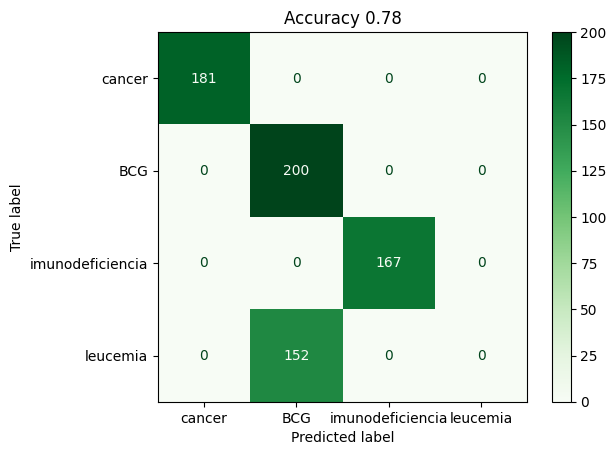


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00       181
          cancer       0.57      1.00      0.72       200
imunodeficiencia       1.00      1.00      1.00       167
        leucemia       0.00      0.00      0.00       152

        accuracy                           0.78       700
       macro avg       0.64      0.75      0.68       700
    weighted avg       0.66      0.78      0.70       700

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_True
6. cat__FOXP3_Normal_True
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
  Atributo_Preprocessado  Passou_Variancia  Selecionado_Final

In [ ]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

### Random Forest

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': 5, 'rf__min_samples_split': 2, 'rf__n_estimators': 200, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7743

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.8286



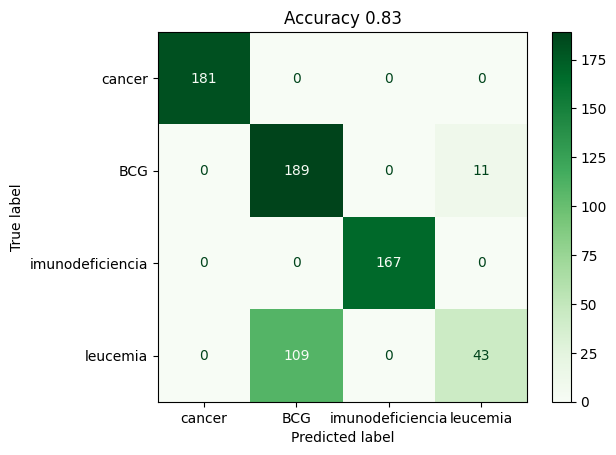


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00       181
          cancer       0.63      0.94      0.76       200
imunodeficiencia       1.00      1.00      1.00       167
        leucemia       0.80      0.28      0.42       152

        accuracy                           0.83       700
       macro avg       0.86      0.81      0.79       700
    weighted avg       0.85      0.83      0.80       700

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_True
6. cat__FOXP3_Normal_True
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
  Atributo_Preprocessado  Passou_Variancia  Selecionado_Final

In [ ]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

### Gradient Boost Machine (GBM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.01, 'gb__max_depth': 3, 'gb__n_estimators': 50, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7829

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.7929



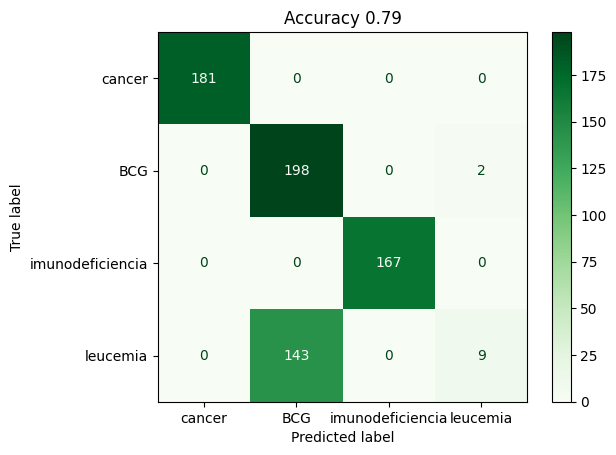


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00       181
          cancer       0.58      0.99      0.73       200
imunodeficiencia       1.00      1.00      1.00       167
        leucemia       0.82      0.06      0.11       152

        accuracy                           0.79       700
       macro avg       0.85      0.76      0.71       700
    weighted avg       0.84      0.79      0.73       700

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_True
6. cat__FOXP3_Normal_True
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
  Atributo_Preprocessado  Passou_Variancia  Selecionado_Final

In [ ]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

### Naive Bayes (NB)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(1.0), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7829

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.7829



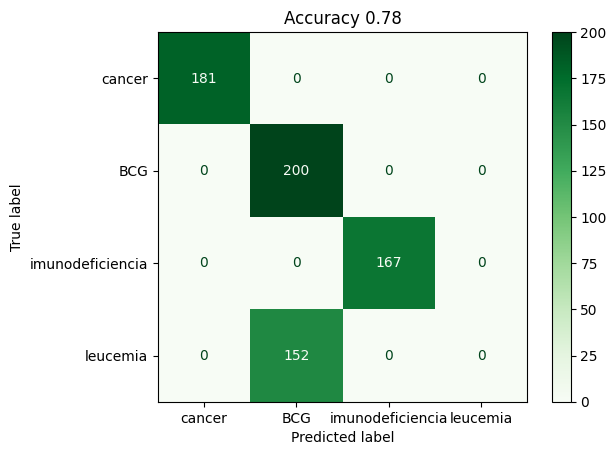


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00       181
          cancer       0.57      1.00      0.72       200
imunodeficiencia       1.00      1.00      1.00       167
        leucemia       0.00      0.00      0.00       152

        accuracy                           0.78       700
       macro avg       0.64      0.75      0.68       700
    weighted avg       0.66      0.78      0.70       700

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_True
6. cat__FOXP3_Normal_True
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
  Atributo_Preprocessado  Passou_Variancia  Selecionado_Final

In [ ]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

### Nearest Neighbour

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10,), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7814

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.7886



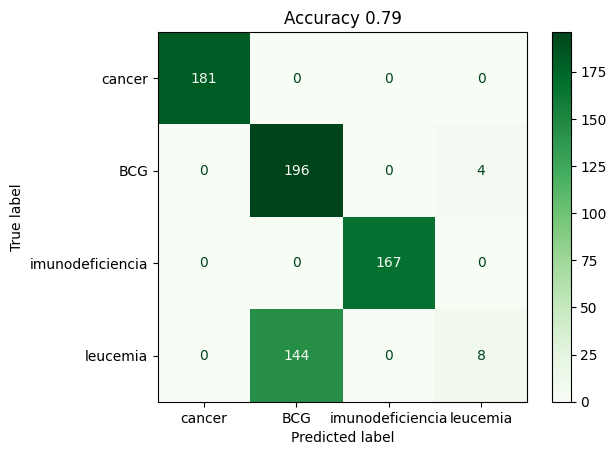


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00       181
          cancer       0.58      0.98      0.73       200
imunodeficiencia       1.00      1.00      1.00       167
        leucemia       0.67      0.05      0.10       152

        accuracy                           0.79       700
       macro avg       0.81      0.76      0.71       700
    weighted avg       0.81      0.79      0.73       700

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_True
6. cat__FOXP3_Normal_True
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
  Atributo_Preprocessado  Passou_Variancia  Selecionado_Final

In [ ]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

## Avaliação métricas de treino

In [ ]:
# Organizando as métricas de treinamento
df_metricas_train = pd.concat(
    [
        metricas_knn.T,
        metricas_svm.T,
        metricas_rf.T,
        metricas_gbm.T,
        metricas_nb.T,
        metricas_nn.T,
    ]
)
df_metricas_train.reset_index(inplace=True)
df_metricas_train["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_train.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_train.head()

,metricas,valores,modelo
0,Acurácia,0.8471,k-NN
1,Precision,0.8460,k-NN
2,Recall,0.8471,k-NN
3,F1-Score,0.8457,k-NN
4,Acurácia,0.7829,SVM


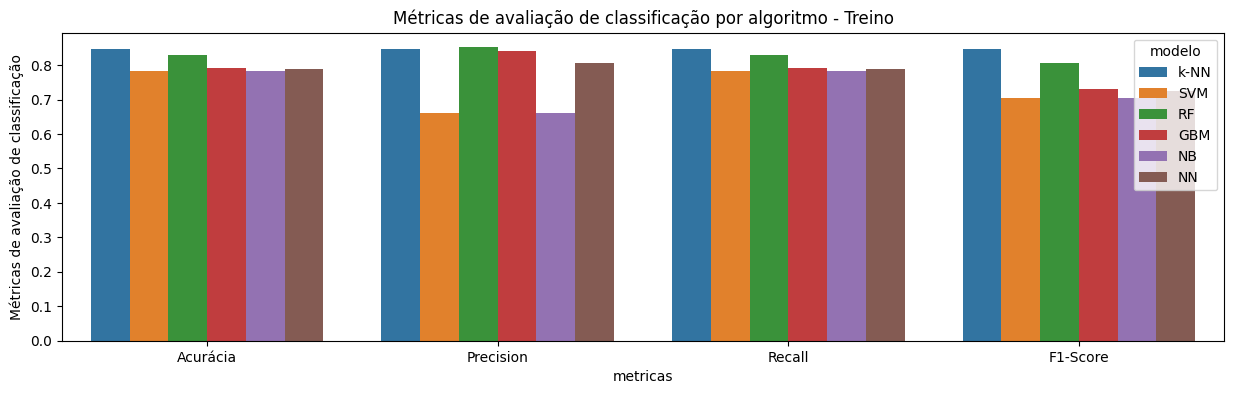

In [ ]:
# Gráfico de barras das métricas de avaliação de clustering para os algoritmos
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo - Treino")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_train,
)
plt.ylabel("Métricas de avaliação de classificação")

plt.show()

In [ ]:
df_train["k-NN"] = pred_knn.copy()
df_train["SVM"] = pred_svm.copy()
df_train["RF"] = pred_rf.copy()
df_train["GBM"] = pred_gbm.copy()
df_train["NB"] = pred_nb.copy()
df_train["NN"] = pred_nn.copy()
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe,k-NN,SVM,RF,GBM,NB,NN
541,-6.605859,587.422573,861.125119,1.728509,True,False,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,True,False,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,False,True,Alto,Alto,Baixo,Baixo,leucemia,cancer,cancer,cancer,cancer,cancer,cancer
422,-4.197952,537.954188,889.391214,1.574182,True,False,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,False,True,Alto,Alto,Baixo,Baixo,leucemia,leucemia,cancer,leucemia,cancer,cancer,leucemia


Salvando a df de treino agora com as predições por modelo de cada instância

In [ ]:
dump(df_train, './df_train_predicoes_classificacao')

['./df_train_predicoes_classificacao']

## Validação

In [ ]:
df_valid.replace({'FOXP3_Alterado': {True: 'Alterado', False:'Normal'}, 'FOXP3_Normal': {True:'Normal', False:'Alterado'},
                  'Igs_Alto': {True: 'Alto', False:'Baixo'}, 'Igs_Baixo':{True:'Baixo', False:'Alto'},
                  'citoc_Alto': {True:'Alto', False: 'Baixo'}, 'citoc_Baixo': {True: 'Baixo', False:'Alto'}}, inplace=True)

### KNN

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7502

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.9050



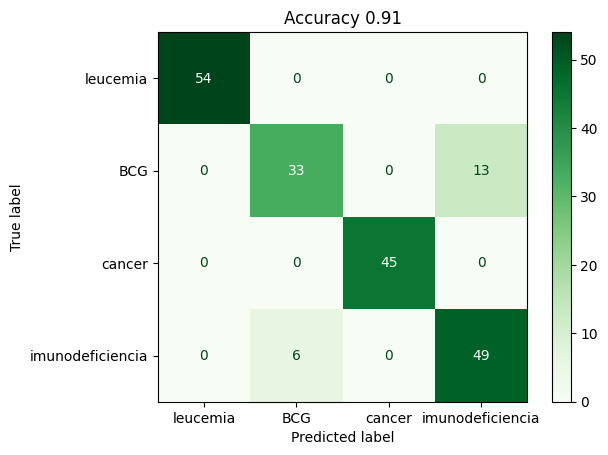


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        54
          cancer       0.85      0.72      0.78        46
imunodeficiencia       1.00      1.00      1.00        45
        leucemia       0.79      0.89      0.84        55

        accuracy                           0.91       200
       macro avg       0.91      0.90      0.90       200
    weighted avg       0.91      0.91      0.90       200

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_Normal
6. cat__FOXP3_Normal_Normal
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
    Atributo_Preprocessado  Passou_Variancia  Selecionado

In [ ]:
classificador = Classifier(df=df_valid)

metricas_knn, pred_knn = classificador.classify(modelo="knn")

### Support Vector Machine (SVM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7951

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.8150



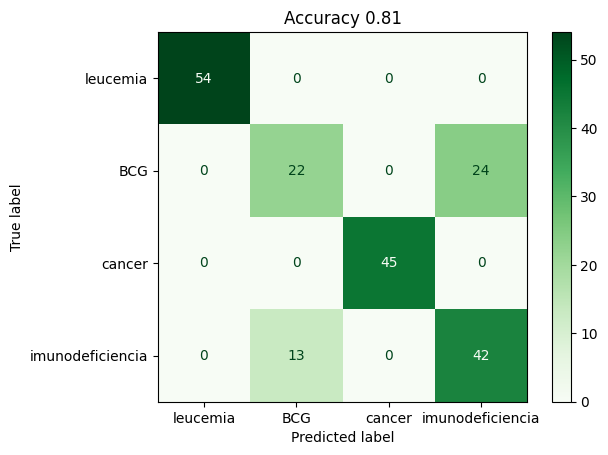


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        54
          cancer       0.63      0.48      0.54        46
imunodeficiencia       1.00      1.00      1.00        45
        leucemia       0.64      0.76      0.69        55

        accuracy                           0.81       200
       macro avg       0.82      0.81      0.81       200
    weighted avg       0.81      0.81      0.81       200

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_Normal
6. cat__FOXP3_Normal_Normal
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
    Atributo_Preprocessado  Passou_Variancia  Selecionado

In [ ]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

### Random Forest

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': 5, 'rf__min_samples_split': 5, 'rf__n_estimators': 50, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7803

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.8600



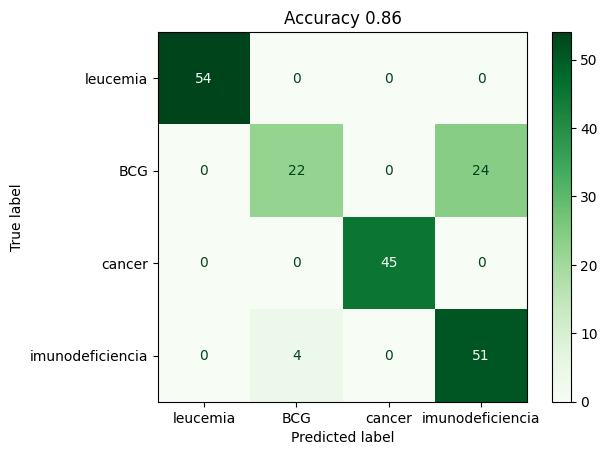


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        54
          cancer       0.85      0.48      0.61        46
imunodeficiencia       1.00      1.00      1.00        45
        leucemia       0.68      0.93      0.78        55

        accuracy                           0.86       200
       macro avg       0.88      0.85      0.85       200
    weighted avg       0.88      0.86      0.85       200

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_Normal
6. cat__FOXP3_Normal_Normal
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
    Atributo_Preprocessado  Passou_Variancia  Selecionado

In [ ]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

### Gradient Boost Machine (GBM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.01, 'gb__max_depth': 3, 'gb__n_estimators': 50, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7950

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.8600



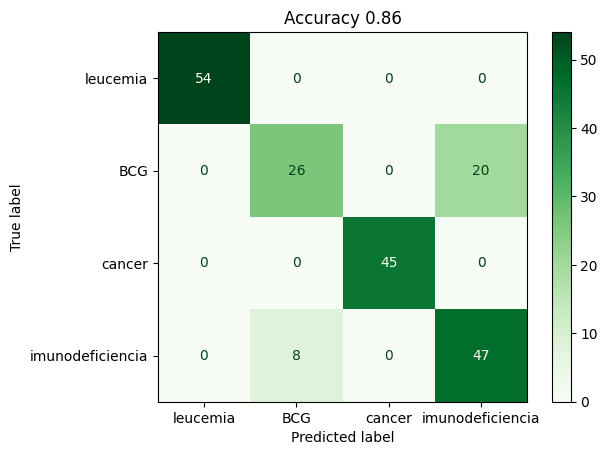


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        54
          cancer       0.76      0.57      0.65        46
imunodeficiencia       1.00      1.00      1.00        45
        leucemia       0.70      0.85      0.77        55

        accuracy                           0.86       200
       macro avg       0.87      0.85      0.86       200
    weighted avg       0.86      0.86      0.86       200

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_Normal
6. cat__FOXP3_Normal_Normal
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
    Atributo_Preprocessado  Passou_Variancia  Selecionado

In [ ]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

### Naive Bayes (NB)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': np.float64(0.1), 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7900

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.8200



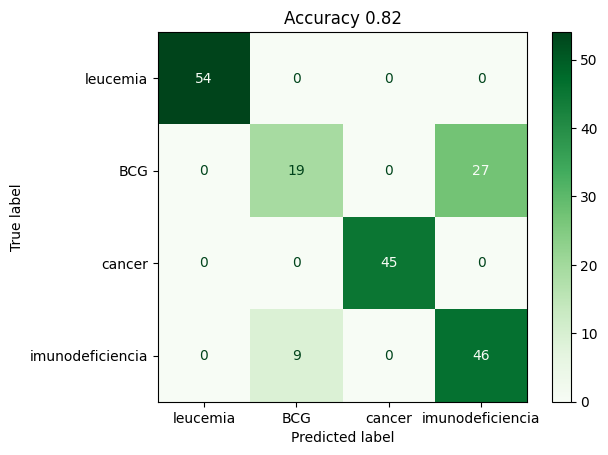


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        54
          cancer       0.68      0.41      0.51        46
imunodeficiencia       1.00      1.00      1.00        45
        leucemia       0.63      0.84      0.72        55

        accuracy                           0.82       200
       macro avg       0.83      0.81      0.81       200
    weighted avg       0.82      0.82      0.81       200

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_Normal
6. cat__FOXP3_Normal_Normal
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
    Atributo_Preprocessado  Passou_Variancia  Selecionado

In [ ]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

### Nearest Neighbour (NN)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (50,), 'mlp__solver': 'adam', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.8002

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.8100



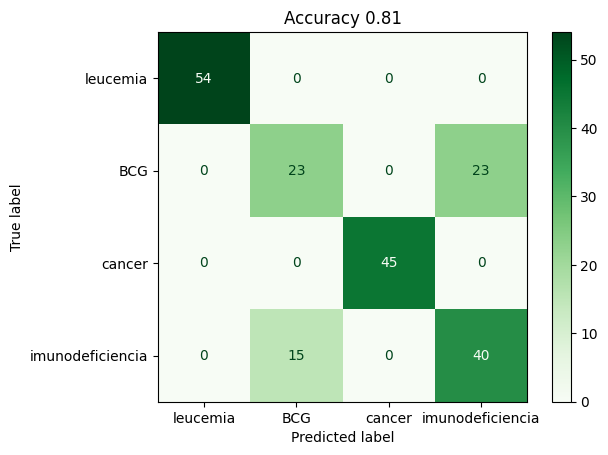


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        54
          cancer       0.61      0.50      0.55        46
imunodeficiencia       1.00      1.00      1.00        45
        leucemia       0.63      0.73      0.68        55

        accuracy                           0.81       200
       macro avg       0.81      0.81      0.81       200
    weighted avg       0.81      0.81      0.81       200

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. cat__FOXP3_Alterado_Normal
6. cat__FOXP3_Normal_Normal
7. cat__Igs_Alto_Baixo
8. cat__Igs_Baixo_Baixo
9. cat__citoc_Alto_Baixo
10. cat__citoc_Baixo_Baixo

--- Status de Cada Atributo no Pipeline ---
    Atributo_Preprocessado  Passou_Variancia  Selecionado

In [ ]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

## Avaliação métricas de validação

In [ ]:
# Organizando as métricas de validacao
df_metricas_valid = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_valid.reset_index(inplace=True)
df_metricas_valid["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_valid.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_valid.head()

,metricas,valores,modelo
0,Acurácia,0.9050,k-NN
1,Precision,0.9070,k-NN
2,Recall,0.9050,k-NN
3,F1-Score,0.9039,k-NN
4,Acurácia,0.8150,SVM


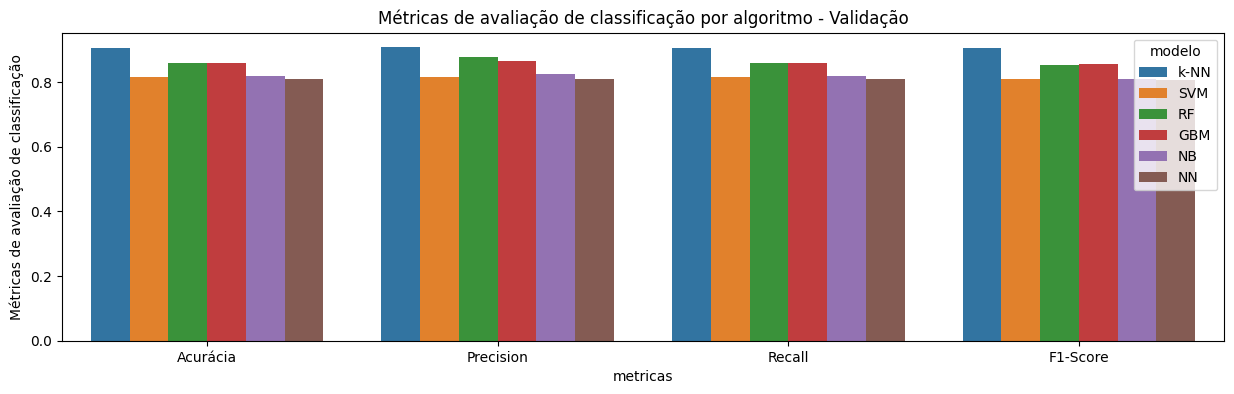

In [ ]:
# Gráfico de barras das métricas de avaliação de clustering para os algoritmos
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo - Validação")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_valid,
)
plt.ylabel("Métricas de avaliação de classificação")

plt.show()

In [ ]:
df_valid["k-NN"] = pred_knn.copy()
df_valid["SVM"] = pred_svm.copy()
df_valid["RF"] = pred_rf.copy()
df_valid["GBM"] = pred_gbm.copy()
df_valid["NB"] = pred_nb.copy()
df_valid["NN"] = pred_nn.copy()
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe,k-NN,SVM,RF,GBM,NB,NN
904,-4.354233,683.860757,702.521323,2.228345,Alterado,Alterado,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,Normal,Normal,Alto,Alto,Baixo,Baixo,leucemia,leucemia,cancer,leucemia,leucemia,leucemia,cancer
139,-2.771307,223.769444,1315.554814,0.532531,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,leucemia,cancer,leucemia,cancer,cancer,cancer
526,-1.810700,364.827049,1268.215382,1.394407,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,cancer,leucemia,leucemia,leucemia,leucemia,leucemia
868,-2.473679,271.804503,1187.576700,0.468055,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,cancer,leucemia,cancer,cancer,leucemia,leucemia


Salvando df de validação com predições por modelo e por instância

In [ ]:
dump(df_valid, './df_valid_predicoes_classificacao')

['./df_valid_predicoes_classificacao']

## Teste

In [ ]:
df_test.replace({'FOXP3_Alterado': {True:'Alterado', False : 'Normal'}, 'FOXP3_Normal':{True:'Normal', False:'Alterado'},
                'Igs_Alto': {True:'Alto', False:'Baixo'}, 'Igs_Baixo':{True:'Baixo', False:'Alto'},
                'citoc_Alto':{True:'Alto', False:'Baixo'}, 'citoc_Baixo':{True: 'Baixo', False:'Alto'}},inplace=True)

In [ ]:
classificador = Classifier(df=df_test)

### KNN

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'manhattan', 'knn__n_neighbors': 1, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.8001
Acurácia final: 0.9600



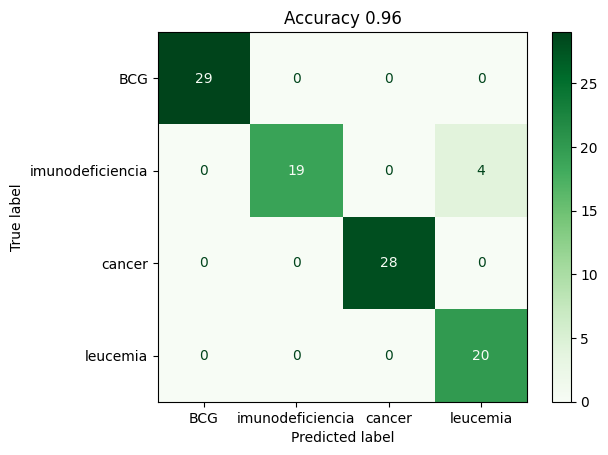


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        29
          cancer       1.00      0.83      0.90        23
imunodeficiencia       1.00      1.00      1.00        28
        leucemia       0.83      1.00      0.91        20

        accuracy                           0.96       100
       macro avg       0.96      0.96      0.95       100
    weighted avg       0.97      0.96      0.96       100

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. num__FOXP3_Alterado
6. num__FOXP3_Normal
7. num__Igs_Alto
8. num__Igs_Baixo
9. num__citoc_Alto
10. num__citoc_Baixo

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log             

In [ ]:

metricas_knn, pred_knn = classificador.classify(modelo="knn")

### Support Vector Machine (SVM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.8001
Acurácia final: 0.8000



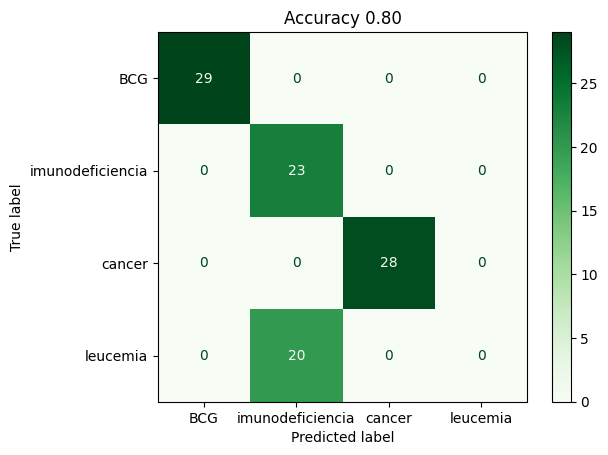


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        29
          cancer       0.53      1.00      0.70        23
imunodeficiencia       1.00      1.00      1.00        28
        leucemia       0.00      0.00      0.00        20

        accuracy                           0.80       100
       macro avg       0.63      0.75      0.67       100
    weighted avg       0.69      0.80      0.73       100

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. num__FOXP3_Alterado
6. num__FOXP3_Normal
7. num__Igs_Alto
8. num__Igs_Baixo
9. num__citoc_Alto
10. num__citoc_Baixo

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log             

In [ ]:
metricas_svm, pred_svm = classificador.classify(modelo="svm")

### Random Forest

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'entropy', 'rf__max_depth': None, 'rf__min_samples_split': 5, 'rf__n_estimators': 100, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7894
Acurácia final: 0.9700



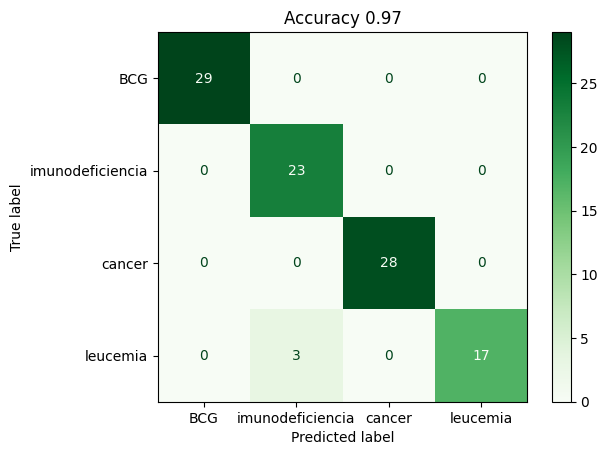


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        29
          cancer       0.88      1.00      0.94        23
imunodeficiencia       1.00      1.00      1.00        28
        leucemia       1.00      0.85      0.92        20

        accuracy                           0.97       100
       macro avg       0.97      0.96      0.96       100
    weighted avg       0.97      0.97      0.97       100

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. num__FOXP3_Alterado
6. num__FOXP3_Normal
7. num__Igs_Alto
8. num__Igs_Baixo
9. num__citoc_Alto
10. num__citoc_Baixo

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log             

In [ ]:
metricas_rf, pred_rf = classificador.classify(modelo="rf")

### Gradient Boost Machine (GBM)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.2, 'gb__max_depth': 3, 'gb__n_estimators': 150, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.8200
Acurácia final: 0.9700



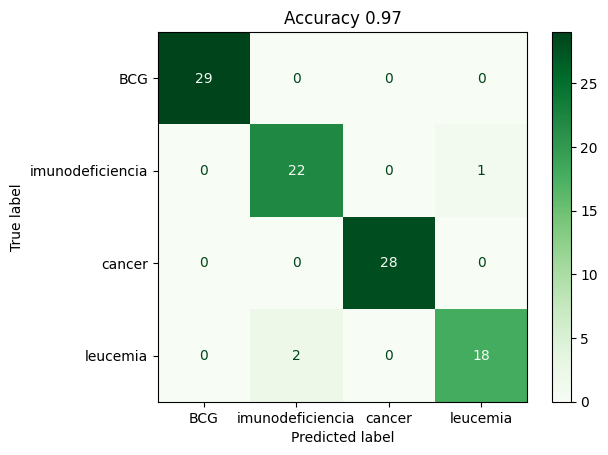


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        29
          cancer       0.92      0.96      0.94        23
imunodeficiencia       1.00      1.00      1.00        28
        leucemia       0.95      0.90      0.92        20

        accuracy                           0.97       100
       macro avg       0.97      0.96      0.96       100
    weighted avg       0.97      0.97      0.97       100

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. num__FOXP3_Alterado
6. num__FOXP3_Normal
7. num__Igs_Alto
8. num__Igs_Baixo
9. num__citoc_Alto
10. num__citoc_Baixo

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log             

In [ ]:
metricas_gbm, pred_gbm = classificador.classify(modelo="gbm")

### Naive Bayes (NB)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'nb__var_smoothing': 1.0, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.7597
Acurácia final: 0.8100



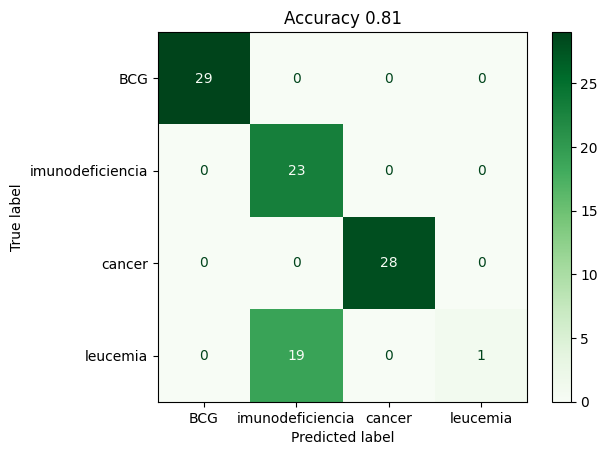


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        29
          cancer       0.55      1.00      0.71        23
imunodeficiencia       1.00      1.00      1.00        28
        leucemia       1.00      0.05      0.10        20

        accuracy                           0.81       100
       macro avg       0.89      0.76      0.70       100
    weighted avg       0.90      0.81      0.75       100

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. num__FOXP3_Alterado
6. num__FOXP3_Normal
7. num__Igs_Alto
8. num__Igs_Baixo
9. num__citoc_Alto
10. num__citoc_Baixo

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log             

In [ ]:
metricas_nb, pred_nb = classificador.classify(modelo="nb")

### Neural Networks (NN)

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (50,), 'mlp__solver': 'lbfgs', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.8102
Acurácia final: 0.9700



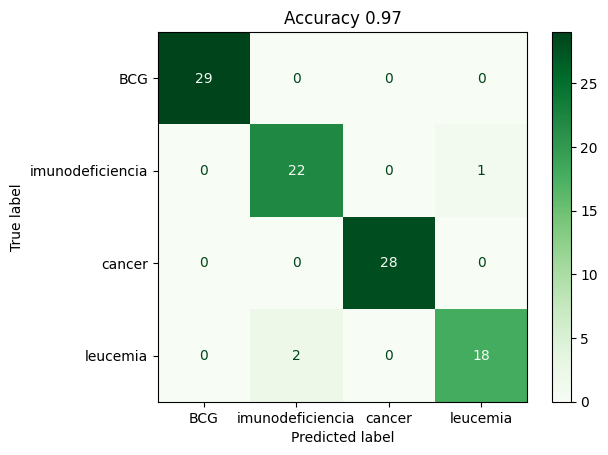


Classification Report:
                  precision    recall  f1-score   support

             BCG       1.00      1.00      1.00        29
          cancer       0.92      0.96      0.94        23
imunodeficiencia       1.00      1.00      1.00        28
        leucemia       0.95      0.90      0.92        20

        accuracy                           0.97       100
       macro avg       0.97      0.96      0.96       100
    weighted avg       0.97      0.97      0.97       100

Total de variáveis originais pré-processadas: 10
Total de variáveis após VarianceThreshold:    10
Total de variáveis selecionadas no modelo:    10

--- Lista das Variáveis Selecionadas ---
1. num__CD34_log
2. num__Lin_B
3. num__Lin_T
4. num__PPD_log
5. num__FOXP3_Alterado
6. num__FOXP3_Normal
7. num__Igs_Alto
8. num__Igs_Baixo
9. num__citoc_Alto
10. num__citoc_Baixo

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__CD34_log             

In [ ]:
metricas_nn, pred_nn = classificador.classify(modelo="nn")

## Avaliação das métricas de teste

In [ ]:
# Organizando as métricas de teste
df_metricas_test = pd.concat(
    [
        metricas_knn.T.copy(),
        metricas_svm.T.copy(),
        metricas_rf.T.copy(),
        metricas_gbm.T.copy(),
        metricas_nb.T.copy(),
        metricas_nn.T.copy(),
    ]
)
df_metricas_test.reset_index(inplace=True)
df_metricas_test["modelo"] = (
    ["k-NN"] * 4 + ["SVM"] * 4 + ["RF"] * 4 + ["GBM"] * 4 + ["NB"] * 4 + ["NN"] * 4
)
df_metricas_test.rename(columns={"index": "metricas", 0: "valores"}, inplace=True)
df_metricas_test.head()

,metricas,valores,modelo
0,Acurácia,0.9600,k-NN
1,Precision,0.9667,k-NN
2,Recall,0.9600,k-NN
3,F1-Score,0.9599,k-NN
4,Acurácia,0.8000,SVM


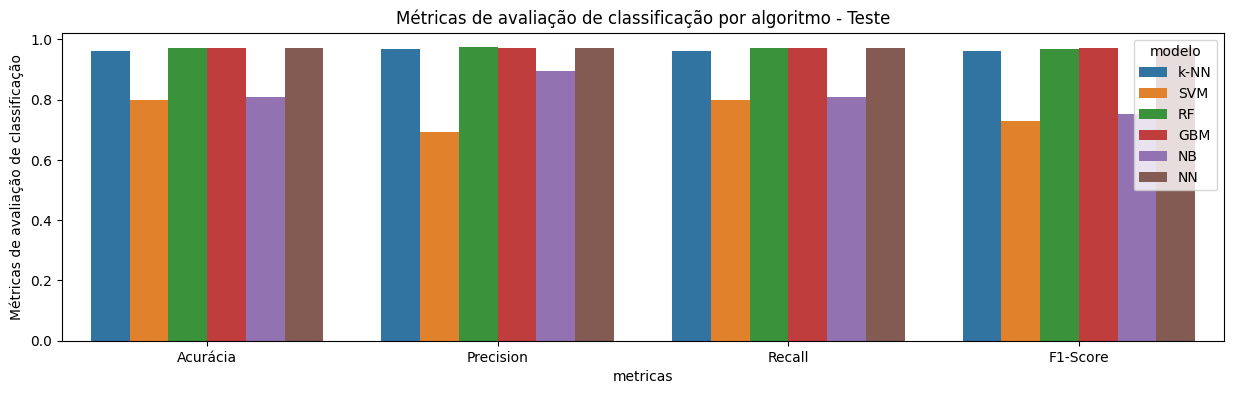

In [ ]:
# Gráfico de barras das métricas de avaliação de clustering para os algoritmos
plt.figure(figsize=(15, 4))
plt.title("Métricas de avaliação de classificação por algoritmo - Teste")
p = sns.barplot(
    x="metricas",
    y="valores",
    hue="modelo",
    data=df_metricas_test,
)
plt.ylabel("Métricas de avaliação de classificação")

plt.show()

In [ ]:
df_test["k-NN"] = pred_knn.copy()
df_test["SVM"] = pred_svm.copy()
df_test["RF"] = pred_rf.copy()
df_test["GBM"] = pred_gbm.copy()
df_test["NB"] = pred_nb.copy()
df_test["NN"] = pred_nn.copy()
df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe,k-NN,SVM,RF,GBM,NB,NN
557,-3.243291,343.587918,1092.448432,1.478703,0,1,1,0,0,1,cancer,leucemia,cancer,cancer,cancer,cancer,cancer
798,-2.082097,308.565265,1514.927999,1.406982,0,1,1,0,0,1,leucemia,leucemia,cancer,leucemia,leucemia,cancer,leucemia
977,-2.154434,208.457031,1317.570437,2.114693,0,1,1,0,0,1,cancer,cancer,cancer,cancer,cancer,cancer,cancer
136,-2.780156,279.316121,1304.394062,1.050797,0,1,1,0,0,1,cancer,cancer,cancer,cancer,cancer,cancer,cancer
575,-4.625737,547.067973,802.296876,2.145163,1,0,0,1,0,1,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia


Salvando a df de teste com as predições por modelo e por instância

In [ ]:
dump(df_test, './df_test_predicoes_classificacao')

['./df_test_predicoes_classificacao']

In [ ]:
df_test.to_csv('./df_test_predicoes_classificacao.csv')

# Avalia Modelos

In [ ]:
# dump(df_train, "./data/08_aula_09_df_train_resultados_classif")
df_train = load("./data/df_resultados_Sofia/df_train_predicoes_classificacao")

# dump(df_valid, "./data/08_aula_09_df_valid_resultados_classif")
df_valid = load("./data/df_resultados_Sofia/df_valid_predicoes_classificacao")

# dump(df_test, "./data/08_aula_09_df_test_resultados_classif")
df_test = load("./data/df_resultados_Sofia/df_test_predicoes_classificacao")

ModuleNotFoundError: No module named 'numpy._core'

In [ ]:
df_train.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe,k-NN,SVM,RF,GBM,NB,NN
541,-6.605859,587.422573,861.125119,1.728509,True,False,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
440,-4.329437,500.185650,801.998581,1.240507,True,False,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
482,-1.748794,208.645029,1299.553614,1.470395,False,True,Alto,Alto,Baixo,Baixo,leucemia,cancer,cancer,cancer,cancer,cancer,cancer
422,-4.197952,537.954188,889.391214,1.574182,True,False,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
778,-1.880539,274.394770,1419.982269,3.714128,False,True,Alto,Alto,Baixo,Baixo,leucemia,leucemia,cancer,leucemia,cancer,cancer,leucemia


In [ ]:
df_valid.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe,k-NN,SVM,RF,GBM,NB,NN
904,-4.354233,683.860757,702.521323,2.228345,Alterado,Alterado,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia
543,-1.963294,237.586357,1456.448090,2.271285,Normal,Normal,Alto,Alto,Baixo,Baixo,leucemia,leucemia,cancer,leucemia,leucemia,leucemia,cancer
139,-2.771307,223.769444,1315.554814,0.532531,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,leucemia,cancer,leucemia,cancer,cancer,cancer
526,-1.810700,364.827049,1268.215382,1.394407,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,cancer,leucemia,leucemia,leucemia,leucemia,leucemia
868,-2.473679,271.804503,1187.576700,0.468055,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,cancer,leucemia,cancer,cancer,leucemia,leucemia


In [ ]:
df_test.head()

,CD34_log,Lin_B,Lin_T,PPD_log,FOXP3_Alterado,FOXP3_Normal,Igs_Alto,Igs_Baixo,citoc_Alto,citoc_Baixo,classe,k-NN,SVM,RF,GBM,NB,NN
557,-3.243291,343.587918,1092.448432,1.478703,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,leucemia,cancer,cancer,cancer,cancer,cancer
798,-2.082097,308.565265,1514.927999,1.406982,Normal,Normal,Alto,Alto,Baixo,Baixo,leucemia,leucemia,cancer,leucemia,leucemia,cancer,leucemia
977,-2.154434,208.457031,1317.570437,2.114693,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,cancer,cancer,cancer,cancer,cancer,cancer
136,-2.780156,279.316121,1304.394062,1.050797,Normal,Normal,Alto,Alto,Baixo,Baixo,cancer,cancer,cancer,cancer,cancer,cancer,cancer
575,-4.625737,547.067973,802.296876,2.145163,Alterado,Alterado,Baixo,Baixo,Baixo,Baixo,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia,imunodeficiencia


In [ ]:
len(df_test)

100

In [ ]:
df_train["k-NN"].value_counts()

k-NN
cancer              217
BCG                 181
imunodeficiencia    167
leucemia            135
Name: count, dtype: int64

In [ ]:
df_valid["k-NN"].value_counts()

k-NN
leucemia            62
BCG                 54
imunodeficiencia    45
cancer              39
Name: count, dtype: int64

In [ ]:
df_test["k-NN"].value_counts()

k-NN
BCG                 29
imunodeficiencia    28
leucemia            22
cancer              21
Name: count, dtype: int64

In [ ]:
def testar_hipotese(df: pd.DataFrame) -> None:
    """
    Testa a hipótese de que a distribuição das classes no treino e no teste é estatisticamente igual (homogênea)
    ou diferente (heterogênea) usando o teste Qui-Quadrado.

    Parâmetros:
        df : pd.DataFrame
            DataFrame contendo as colunas 'Dataset' e 'Classe_Predita'.
        modelo : str
            Nome do modelo para exibição nos resultados.
    Retorna:
        None
    """
    # 3. Criando a Tabela de Contingência (Frequências Observadas)
    tabela_contingencia = pd.crosstab(df["Dataset"], df["Classe_Predita"])
    print("Tabela de Contingência (Observada):")
    print(tabela_contingencia)
    print("-" * 40)

    # 4. Realizando o Teste Qui-Quadrado
    chi2, p_valor, graus_liberdade, frequencias_esperadas = chi2_contingency(
        tabela_contingencia
    )

    # 5. Exibindo os resultados
    print(f"Estatística Qui-Quadrado: {chi2:.4f}")
    print(f"Graus de Liberdade: {graus_liberdade}")
    print(f"Valor-p: {p_valor:.4f}")

    # 6. Tomada de Decisão (usando nível de significância de 5%)
    alpha = 0.05
    print("\nConclusão:")
    if p_valor < alpha:
        print(
            "Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea)."
        )
    else:
        print(
            "Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea)."
        )

    return None

In [ ]:
modelo = "k-NN"
link = f"./df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_knn = load(link)

df_knn.to_csv('')
print(modelo)
display(df_knn.value_counts())
testar_hipotese(df_knn)

k-NN


Dataset  Classe_Predita  
Treino   cancer              217
         BCG                 181
         imunodeficiencia    167
         leucemia            135
Teste    BCG                  29
         imunodeficiencia     28
         leucemia             22
         cancer               21
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  BCG  cancer  imunodeficiencia  leucemia
Dataset                                                
Teste            29      21                28        22
Treino          181     217               167       135
----------------------------------------
Estatística Qui-Quadrado: 4.2150
Graus de Liberdade: 3
Valor-p: 0.2392

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [ ]:
modelo = "SVM"
link = f"./Resultados Classificação/df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_svm = load(link)
print(modelo)
display(df_svm.value_counts())
testar_hipotese(df_svm)

SVM


Dataset  Classe_Predita  
Treino   cancer              352
         BCG                 181
         imunodeficiencia    167
Teste    cancer               43
         BCG                  29
         imunodeficiencia     28
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  BCG  cancer  imunodeficiencia
Dataset                                      
Teste            29      43                28
Treino          181     352               167
----------------------------------------
Estatística Qui-Quadrado: 1.8861
Graus de Liberdade: 2
Valor-p: 0.3894

Conclusão:
Falhamos em rejeitar H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE IGUAL (Homogênea).


In [ ]:
modelo = "RF"
link = f"./Resultados Classificação/df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_rf = load(link)
print(modelo)
display(df_rf.value_counts())
testar_hipotese(df_rf)

RF


Dataset  Classe_Predita  
Treino   cancer              298
         BCG                 181
         imunodeficiencia    167
         leucemia             54
Teste    BCG                  29
         imunodeficiencia     28
         cancer               26
         leucemia             17
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  BCG  cancer  imunodeficiencia  leucemia
Dataset                                                
Teste            29      26                28        17
Treino          181     298               167        54
----------------------------------------
Estatística Qui-Quadrado: 15.3794
Graus de Liberdade: 3
Valor-p: 0.0015

Conclusão:
Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea).


In [ ]:
modelo = "GBM"
link = f"./Resultados Classificação/df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_gbm = load(link)
print(modelo)
display(df_gbm.value_counts())
testar_hipotese(df_gbm)

GBM


Dataset  Classe_Predita  
Treino   cancer              341
         BCG                 181
         imunodeficiencia    167
Teste    BCG                  29
         imunodeficiencia     28
         cancer               24
         leucemia             19
Treino   leucemia             11
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  BCG  cancer  imunodeficiencia  leucemia
Dataset                                                
Teste            29      24                28        19
Treino          181     341               167        11
----------------------------------------
Estatística Qui-Quadrado: 83.5355
Graus de Liberdade: 3
Valor-p: 0.0000

Conclusão:
Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea).


In [ ]:
modelo = "NB"
link = f"./Resultados Classificação/df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_nb = load(link)
print(modelo)
display(df_nb.value_counts())
testar_hipotese(df_nb)

NB


Dataset  Classe_Predita  
Treino   cancer              352
         BCG                 181
         imunodeficiencia    167
Teste    cancer               42
         BCG                  29
         imunodeficiencia     28
         leucemia              1
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  BCG  cancer  imunodeficiencia  leucemia
Dataset                                                
Teste            29      42                28         1
Treino          181     352               167         0
----------------------------------------
Estatística Qui-Quadrado: 9.1651
Graus de Liberdade: 3
Valor-p: 0.0272

Conclusão:
Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea).


In [ ]:
modelo = "NN"
link = f"./Resultados Classificação/df_classified_{modelo}"
dump(
    pd.DataFrame(
        {
            "Dataset": ["Treino"] * 700 + ["Teste"] * 100,
            "Classe_Predita": np.concatenate(
                [df_train[modelo].values, df_test[modelo].values]
            ),
        }
    ),
    link,
)
df_nn = load(link)
print(modelo)
display(df_nn.value_counts())
testar_hipotese(df_nn)

NN


Dataset  Classe_Predita  
Treino   cancer              340
         BCG                 181
         imunodeficiencia    167
Teste    BCG                  29
         imunodeficiencia     28
         cancer               24
         leucemia             19
Treino   leucemia             12
Name: count, dtype: int64

Tabela de Contingência (Observada):
Classe_Predita  BCG  cancer  imunodeficiencia  leucemia
Dataset                                                
Teste            29      24                28        19
Treino          181     340               167        12
----------------------------------------
Estatística Qui-Quadrado: 80.0261
Graus de Liberdade: 3
Valor-p: 0.0000

Conclusão:
Rejeitamos H0: A distribuição das classes no treino e no teste é ESTATISTICAMENTE DIFERENTE (Heterogênea).
